# Política industrial nos PPAs de Santa Catarina (2004-2027)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andreydeps/tcc-politica-industrial-sc/blob/main/notebooks/TCC.ipynb)

TCC de Andrey de Paula e Silva (Ciências Econômicas, UFSC). O notebook já está salvo com as saídas; para rodar de novo no Colab, use *Ambiente de execução > Executar tudo*. A primeira célula baixa o repositório e instala as dependências (inclusive o modelo `pt_core_news_lg` do spaCy, cerca de 500 MB), o que leva alguns minutos.


In [ ]:
# SETUP_COLAB: no Google Colab, baixa o repositório e instala as dependências.
# No computador local esta célula não faz nada.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tcc"):
        !git clone -q https://github.com/andreydeps/tcc-politica-industrial-sc.git /content/tcc
    %cd /content/tcc
    !pip -q install pdfplumber wordcloud
    !python -m spacy download pt_core_news_lg -q

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber
import spacy
from wordcloud import WordCloud
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Raiz do projeto: o notebook fica em notebooks/, entao sobe um nivel
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
DIR_PPA = RAIZ / "dados" / "ppa"
DIR_SAIDAS = RAIZ / "saidas"
DIR_SAIDAS.mkdir(exist_ok=True)

ordem_periodos = ["2004-2007", "2008-2011", "2012-2015", "2016-2019", "2020-2023", "2024-2027"]

In [2]:
# modelo de linguagem em português (instalado no setup do ambiente:
# python -m spacy download pt_core_news_lg)
nlp = spacy.load("pt_core_news_lg")

In [3]:
caminhos = {
    "2004-2007": DIR_PPA / "ppa_2004_2007.pdf",
    "2008-2011": DIR_PPA / "ppa_2008_2011.pdf",
    "2012-2015": DIR_PPA / "ppa_2012_2015.pdf",
    "2016-2019": DIR_PPA / "ppa_2016_2019.pdf",
    "2020-2023": DIR_PPA / "ppa_2020_2023_v2.pdf",
    "2024-2027": DIR_PPA / "ppa_2024_2027.pdf",
}

duas_colunas = set()

In [4]:
# Códigos de programa considerados política industrial/competitividade econômica,
# por período. Levantados manualmente lendo cada Anexo Único.
codigos_industria = {
    # 2004-2007 usa outra numeração de códigos (ver equivalencia_2004 na célula de continuidade)
    "2004-2007": ["0410", "0490", "0510", "0530", "0540", "0570", "0580", "0230", "0970"],
    "2008-2011": ["0200", "0210", "0230", "0250"],
    "2012-2015": ["0200", "0210", "0212", "0230", "0250", "0310", "0342", "0346"],
    "2016-2019": ["0200", "0210", "0212", "0230", "0310", "0342", "0346"],
    "2020-2023": ["0200", "0210", "0212", "0230", "0310", "0342", "0346"],
    "2024-2027": ["0200", "0210", "0230", "0310", "0342", "0353", "0354"],
}

In [5]:
# Regex geral: usado por 2012-2015, 2016-2019, 2020-2023 e 2024-2027
padrao = re.compile(
    r"PROGRAMA\s+(?P<codigo>\d{4})\s+(?P<nome>.*?)\s+"
    r"(?:ÓRGÃO|UNIDADE) RESPONSÁVEL\s+(?P<orgao>.*?)\s+"
    r"OBJETIVO\s+(?P<objetivo>.*?)\s+"
    r"JUSTIFICATIVA\s+(?P<justificativa>.*?)\s+"
    r"PÚBLICO-ALVO",
    re.DOTALL
)

# Regex específico do 2008-2011: rótulos em Título Case. Nome/órgão travados
# numa linha só (sem DOTALL nessa parte) pra não vazar pra blocos de tabela
# de ações/subações soltos no meio do documento.
padrao_2008 = re.compile(
    r"(?P<codigo>\d{4})\s+(?P<nome>[^\n]+?)\s*Tipo\s+\S+\s*\n"
    r"Órgão Responsável\s+(?P<orgao>[^\n]+?)\s*Horizonte Temporal.*?\n"
    r"Objetivo\s+(?P<objetivo>.*?)"
    r"Justificativa\s+(?P<justificativa>.*?)"
    r"Público Alvo",
    re.DOTALL,
)

# Remove o cabeçalho/rodapé repetido a cada página do 2008-2011, pra não
# contaminar objetivo/justificativa quando um campo atravessa virada de página.
rodape_2008 = re.compile(
    r"Página:\s*\d+\s*de\s*283.*?OGE\s*OF",
    re.DOTALL,
)

# Regex específico do 2004-2007: mesma família do 2008-2011, mas com Tipo de várias palavras,
# nome e órgão que podem continuar na linha seguinte (grupos nome2 e orgao2) e linhas só com espaços.
padrao_2004 = re.compile(
    r"(?m)^[ \t]*(?P<codigo>\d{4})[ \t]+(?P<nome>[^\n]+?)[ \t]+Tipo[ \t]+(?P<tipo>[^\n]+?)[ \t]*\n"
    r"(?P<nome2>(?![ \t]*Órgão Responsável)[^\n]*\n)?\s*"
    r"Órgão Responsável[ \t]+(?P<orgao>[^\n]+?)[ \t]+Horizonte Temporal[^\n]*\n"
    r"(?P<orgao2>(?![ \t]*Objetivo)[^\n]*\n)?\s*"
    r"Objetivo\s+(?P<objetivo>.*?)"
    r"Justificativa\s+(?P<justificativa>.*?)"
    r"Público Alvo",
    re.DOTALL,
)

# Cabeçalho e rodapé repetidos a cada página do 2004-2007
rodape_2004 = re.compile(
    r"Página:\s*\d+\s*de\s*433"
    r"|ESTADO DE SANTA CATARINA\s+ANEXO ÚNICO\s+Plano Plurianual 2004 - 2007\s+\d{4}/\d{4}\s+\d{4}/\d{4}\s+"
    r"PROGRAMA/AÇÕES/SUBAÇÕES\s+PRODUTO UNIDADE FÍSICO\s+OGE\s+OF"
)

In [6]:
def processa_ppa(caminho, periodo, duas_colunas=False, regex=None, limpar_regex=None):
    regex = regex or padrao
    with pdfplumber.open(caminho) as pdf:
        texto = ""
        for pagina in pdf.pages:
            if duas_colunas:
                largura, altura = pagina.width, pagina.height
                esquerda = pagina.crop((0, 0, largura/2, altura)).extract_text() or ""
                direita = pagina.crop((largura/2, 0, largura, altura)).extract_text() or ""
                texto += esquerda + "\n" + direita
            else:
                texto += pagina.extract_text() or ""

    if limpar_regex is not None:
        texto = limpar_regex.sub(" ", texto)

    matches = list(regex.finditer(texto))
    print(f"{periodo}: achei {len(matches)} blocos com programa vinculado")

    if len(matches) == 0:
        print(f"AVISO: {periodo} não bateu com o padrão atual")
        return pd.DataFrame(columns=["codigo", "nome", "orgao", "objetivo", "justificativa", "periodo"])

    registros = []
    for m in matches:
        d = m.groupdict()
        if "nome2" in d:  # 2004-2007: nome e órgão podem continuar na linha seguinte
            d["nome"] = " ".join((d["nome"] + " " + (d.pop("nome2") or "")).split())
            d["orgao"] = " ".join((d["orgao"] + " " + (d.pop("orgao2") or "")).split())
            d.pop("tipo", None)
        registros.append(d)
    df = pd.DataFrame(registros)
    # Em alguns blocos (ex.: 0310 de 2024-2027) o rótulo "Público Alvo:" aparece dentro da justificativa,
    # antes do rótulo PÚBLICO-ALVO que fecha o regex. Corta a justificativa nesse ponto.
    corte_publico = re.compile(r"\s*p[úu]blico[\s-]*alvo\s*:", re.IGNORECASE)
    df["justificativa"] = df["justificativa"].apply(lambda t: corte_publico.split(t, maxsplit=1)[0])
    df["periodo"] = periodo
    df = df.drop_duplicates(subset=["codigo", "objetivo"], keep="first")

    codigos_periodo = codigos_industria.get(periodo, [])
    df_industria = df[df["codigo"].isin(codigos_periodo)]
    return df_industria

In [7]:
regex_por_periodo = {"2004-2007": padrao_2004, "2008-2011": padrao_2008}
limpar_por_periodo = {"2004-2007": rodape_2004, "2008-2011": rodape_2008}

resultados = []
for periodo, caminho in caminhos.items():
    resultados.append(
        processa_ppa(
            caminho,
            periodo,
            duas_colunas=(periodo in duas_colunas),
            regex=regex_por_periodo.get(periodo),
            limpar_regex=limpar_por_periodo.get(periodo),
        )
    )

df_todos = pd.concat(resultados, ignore_index=True)
df_todos

2004-2007: achei 118 blocos com programa vinculado


2008-2011: achei 50 blocos com programa vinculado


2012-2015: achei 115 blocos com programa vinculado


2016-2019: achei 107 blocos com programa vinculado


2020-2023: achei 108 blocos com programa vinculado


2024-2027: achei 104 blocos com programa vinculado


,codigo,nome,orgao,objetivo,justificativa,periodo
0,0230,"Pesquisa Agropecuária e Aqüícola, Assistência ...",Secretaria de Estado da Agricultura e Desenvol...,"Disponibilizar aos agricultores, aqüicultores ...","A agropecuária, incluindo a aqüicultura e a pe...",2004-2007
1,0410,Inclusão Digital,"Secretaria de Estado da Educação, Ciência e Te...",Consolidar como a porta de entrada das comunid...,"Equipar o órgão central, gerências regionais e...",2004-2007
2,0490,"Fomento à Pesquisa, Tecnologia e Inovação","Secretaria de Estado da Educação, Ciência e Te...",Estimular a criação e utilização de novas tecn...,"Subutilização de tecnologias, gerando ineficiê...",2004-2007
3,0510,Gerenciamento de Informações para o Desenvolvi...,Secretaria de Estado do Planejamento,"Disponibilizar informações estatísticas, geogr...",Suprir a falta de informações necessárias ao p...,2004-2007
4,0530,Geração de Emprego e Renda,Secretaria de Estado do Desenvolvimento Social...,Aumentar postos de trabalho.\n,Altos índices de desemprego e exclusão social.\n,2004-2007
5,0540,Desenvolvimento da Micro e Pequena Empresa Cat...,Secretaria de Estado da Fazenda,"Apoiar a criação, ampliação, modernização, tra...","Concessão de linhas de crédito a microempresa,...",2004-2007
6,0570,Comércio Exterior e Relações Internacionais,Gabinete do Governador do Estado,Estimular a participação das empresas catarine...,Potencial não aproveitado de participação da e...,2004-2007
7,0580,Promoção da Competitividade da Economia Catari...,Secretaria de Estado do Planejamento,Fomentar a atividade produtiva no estado.\n,Necessidade de ampliar o acesso ao emprego e à...,2004-2007
8,0970,Desenvolvimento Regional e Municipal,Secretaria de Estado do Planejamento,Realização e participação em ações de desenvol...,Participar em projetos municipais e comunitári...,2004-2007
9,0200,Competitividade e Excelência Econômica,Secretaria de Estado do Desenvolvimento Econômico,Fomentar a atividade produtiva no estado e pro...,O ambiente externo é favorável ao comércio nac...,2008-2011


In [8]:
# Lematiza objetivo + justificativa de cada programa (normaliza o texto antes do TF-IDF)
def lematizar(texto):
    doc = nlp(texto)
    return " ".join(
        token.lemma_.lower()
        for token in doc
        if not token.is_stop and not token.is_punct and not token.is_space and token.is_alpha
        and token.pos_ in {"NOUN", "VERB", "ADJ"}
    )

df_todos["texto_completo"] = df_todos["objetivo"] + " " + df_todos["justificativa"]
df_todos["texto_lematizado"] = df_todos["texto_completo"].apply(lematizar)
df_todos[["periodo", "codigo", "texto_lematizado"]]

,periodo,codigo,texto_lematizado
0,2004-2007,0230,disponibilizar agricultor aqüicultor pescador ...
1,2004-2007,0410,consolidar porta entrada comunidade educaciona...
2,2004-2007,0490,estimular criação utilização tecnologia tecnol...
3,2004-2007,0510,disponibilizar informação estatístico geográfi...
4,2004-2007,0530,aumentar posto trabalho alto índice desemprego...
5,2004-2007,0540,apoiar criação ampliação modernização transfer...
6,2004-2007,0570,estimular participação empresa catarinense est...
7,2004-2007,0580,fomentar atividade produtivo necessidade ampli...
8,2004-2007,0970,realização participação ação desenvolvimento r...
9,2008-2011,0200,fomentar atividade produtivo promover diversif...


In [9]:
# Salva o corpus (um programa por linha, com texto lematizado) para as análises seguintes,
# como o snowballing do léxico, sem precisar reextrair os PDFs nem relematizar.
df_todos.to_csv(DIR_SAIDAS / "corpus_programas.csv", index=False, encoding="utf-8")

In [10]:
# Quantidade de programas de política industrial por período
resumo = df_todos.groupby("periodo").size().reindex(ordem_periodos).rename("qtd_programas_industria")
print(resumo)
print(f"\nTotal de programas analisados: {resumo.sum()}")

periodo
2004-2007    9
2008-2011    4
2012-2015    8
2016-2019    7
2020-2023    7
2024-2027    7
Name: qtd_programas_industria, dtype: int64

Total de programas analisados: 42


In [11]:
texto_por_periodo = df_todos.groupby("periodo")["texto_lematizado"].apply(lambda textos: " ".join(textos))
texto_por_periodo = texto_por_periodo.reindex(ordem_periodos)

vectorizer = TfidfVectorizer(max_features=200)
matriz_tfidf = vectorizer.fit_transform(texto_por_periodo)

termos = vectorizer.get_feature_names_out()
df_tfidf = pd.DataFrame(matriz_tfidf.toarray(), index=texto_por_periodo.index, columns=termos)

for periodo in df_tfidf.index:
    print(f"=== {periodo} ===")
    print(df_tfidf.loc[periodo].sort_values(ascending=False).head(15))
    print()

=== 2004-2007 ===


participação       0.458880
social             0.317689
rural              0.238266
alto               0.229440
tecnologia         0.203697
desenvolvimento    0.203697
estimular          0.188144
criação            0.176323
informação         0.176323
pesqueiro          0.158844
serviço            0.152773
regional           0.152773
catarinense        0.152773
econômico          0.152773
empresa            0.152773
Name: 2004-2007, dtype: float64

=== 2008-2011 ===
acesso         0.286938
população      0.265812
rural          0.232645
incubadora     0.224027
tecnológico    0.198891
digital        0.183705
propiciar      0.183705
base           0.172163
promover       0.172163
inovação       0.172163
informação     0.172163
cenário        0.155097
centro         0.155097
pescador       0.155097
favorável      0.155097
Name: 2008-2011, dtype: float64

=== 2012-2015 ===
inovação        0.310564
tecnológico     0.209288
acesso          0.207043
catarinense     0.179390
economia        0.

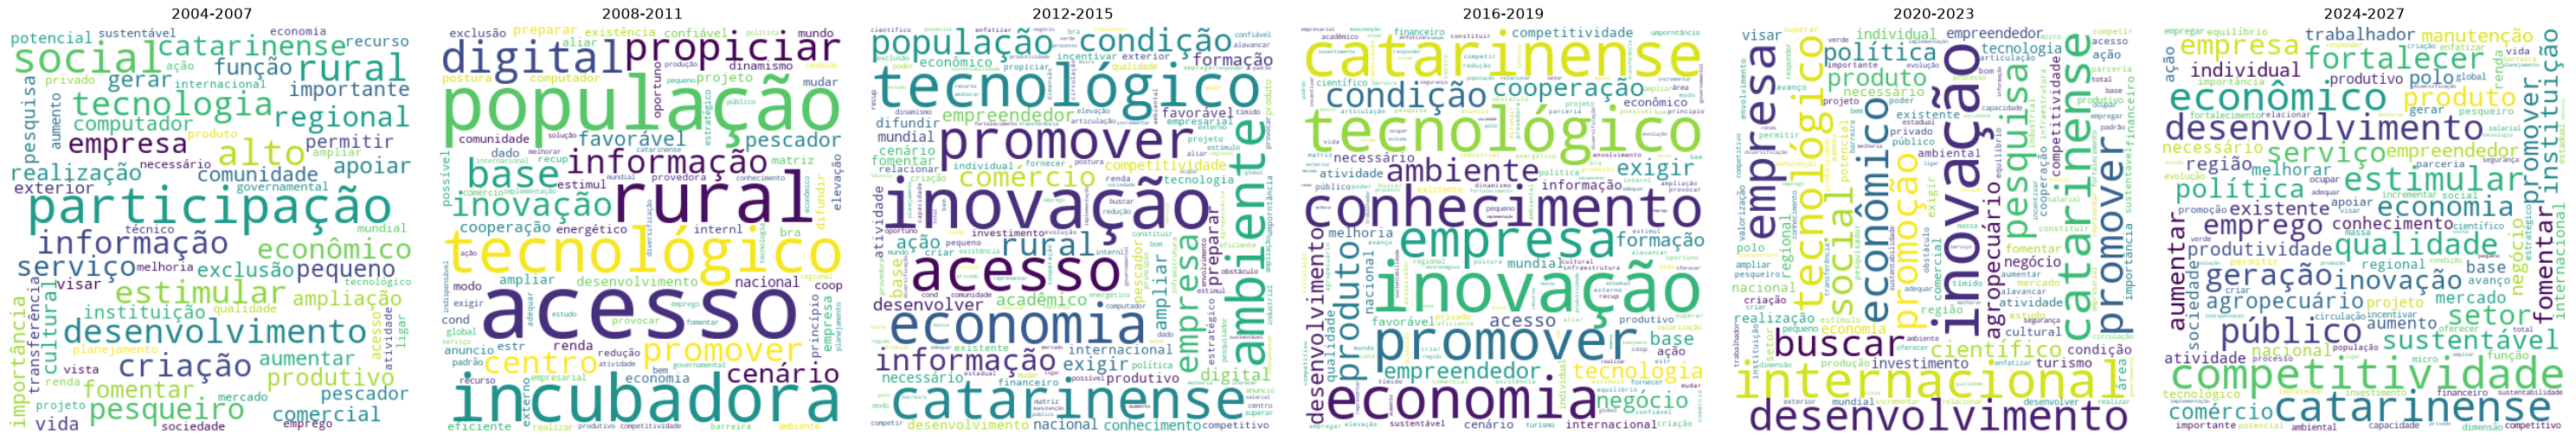

In [12]:
# Wordcloud com o peso TF-IDF de cada termo, por período
fig, axes = plt.subplots(1, 6, figsize=(30, 5))
for ax, periodo in zip(axes, df_tfidf.index):
    freq = {termo: peso for termo, peso in df_tfidf.loc[periodo].items() if peso > 0}
    wc = WordCloud(width=400, height=400, background_color="white").generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(periodo)
    ax.axis("off")
plt.tight_layout()
plt.savefig(DIR_SAIDAS / "wordcloud_tfidf_por_periodo.png", dpi=150, bbox_inches="tight")
plt.show()

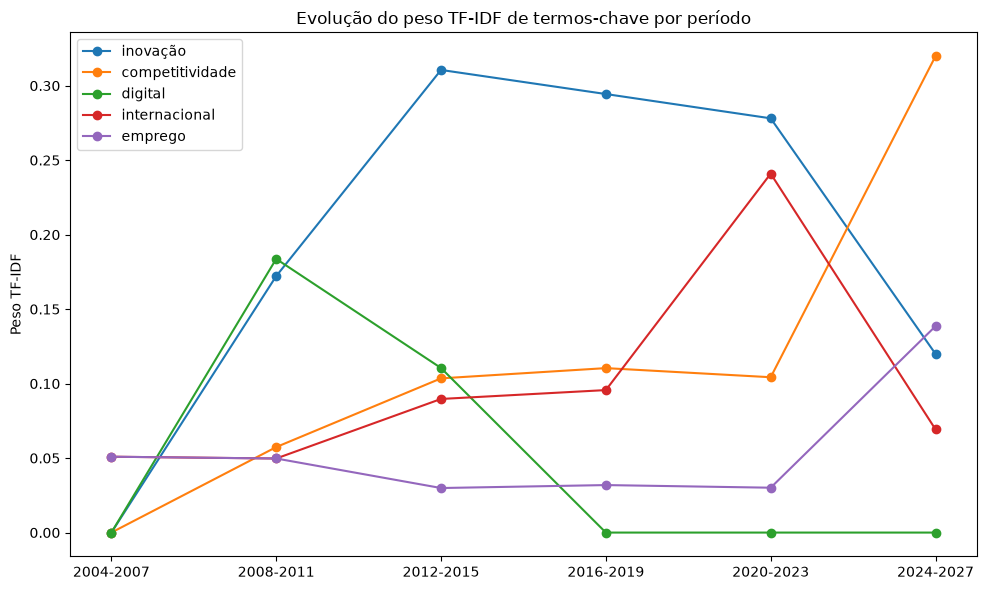

In [13]:
# Evolução do peso TF-IDF de termos-chave ao longo dos 5 períodos
termos_chave = ["inovação", "competitividade", "digital", "internacional", "emprego"]
termos_disponiveis = [t for t in termos_chave if t in df_tfidf.columns]
if len(termos_disponiveis) < len(termos_chave):
    print("Termos não encontrados no vocabulário TF-IDF:", set(termos_chave) - set(termos_disponiveis))

plt.figure(figsize=(10, 6))
for termo in termos_disponiveis:
    plt.plot(df_tfidf.index, df_tfidf[termo], marker="o", label=termo)

plt.title("Evolução do peso TF-IDF de termos-chave por período")
plt.ylabel("Peso TF-IDF")
plt.legend()
plt.tight_layout()
plt.savefig(DIR_SAIDAS / "evolucao_termos_chave_tfidf.png", dpi=150, bbox_inches="tight")
plt.show()

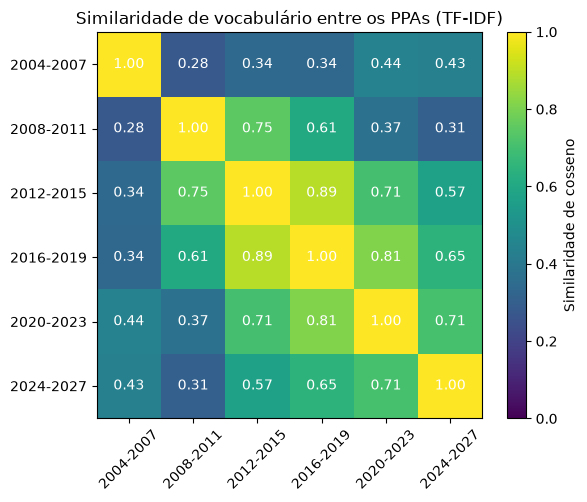

In [14]:
# Similaridade de cosseno entre os vetores TF-IDF: quão parecido é o vocabulário entre PPAs
similaridade = cosine_similarity(matriz_tfidf)
df_similaridade = pd.DataFrame(similaridade, index=ordem_periodos, columns=ordem_periodos)

plt.figure(figsize=(6, 5))
plt.imshow(df_similaridade, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Similaridade de cosseno")
plt.xticks(range(len(ordem_periodos)), ordem_periodos, rotation=45)
plt.yticks(range(len(ordem_periodos)), ordem_periodos)
for i in range(len(ordem_periodos)):
    for j in range(len(ordem_periodos)):
        plt.text(j, i, f"{df_similaridade.iloc[i, j]:.2f}", ha="center", va="center", color="white")
plt.title("Similaridade de vocabulário entre os PPAs (TF-IDF)")
plt.tight_layout()
plt.savefig(DIR_SAIDAS / "similaridade_cosseno_entre_ppas.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# O PPA 2004-2007 usa outra numeração de códigos. Para a continuidade, cada programa dele recebe a
# "série" do programa equivalente nos períodos seguintes. PROPOSTA a validar com o orientador.
equivalencia_2004 = {
    "0580": "0200",  # Promoção da Competitividade da Economia Catarinense -> Competitividade e Excelência Econômica
    "0490": "0230",  # Fomento à Pesquisa, Tecnologia e Inovação -> INOVAR / CTI
    "0230": "0310",  # Pesquisa Agropecuária e Aquícola, Assistência Técnica e Extensão -> Agronegócio Competitivo
    "0540": "0342",  # Micro e Pequena Empresa (Pró-Emprego) -> PREC (equivalência incerta)
    "0570": "0212",  # Comércio Exterior e Relações Internacionais
    "0410": "0250",  # Inclusão Digital
    "0510": "0210",  # Gerenciamento de Informações para o Desenvolvimento -> Estudos, Projetos e Informações Estratégicas
    "0530": "0354",  # Geração de Emprego e Renda -> Trabalho, Emprego e Renda (equivalência incerta)
    "0970": "0970-2004",  # Desenvolvimento Regional e Municipal: sem equivalente claro, série própria
}
df_todos["serie"] = [
    equivalencia_2004.get(cod, cod) if per == "2004-2007" else cod
    for cod, per in zip(df_todos["codigo"], df_todos["periodo"])
]

continuidade = df_todos.groupby("serie")["periodo"].apply(lambda p: sorted(set(p))).reset_index()
continuidade["qtd_periodos"] = continuidade["periodo"].apply(len)

nome_mais_recente = df_todos.sort_values("periodo").groupby("serie")["nome"].last()
continuidade["nome"] = continuidade["serie"].map(nome_mais_recente)
continuidade = continuidade[["serie", "nome", "periodo", "qtd_periodos"]]
continuidade.sort_values("qtd_periodos", ascending=False)

,serie,nome,periodo,qtd_periodos
0,0200,Competitividade e Excelência Econômica,"[2004-2007, 2008-2011, 2012-2015, 2016-2019, 2...",6
1,0210,Desenvolvimento Regional Integrado,"[2004-2007, 2008-2011, 2012-2015, 2016-2019, 2...",6
3,0230,"CTI - Fomento à Ciência, Tecnologia e Inovação","[2004-2007, 2008-2011, 2012-2015, 2016-2019, 2...",6
6,0342,Revitalização da Economia Catarinense - PREC,"[2004-2007, 2012-2015, 2016-2019, 2020-2023, 2...",5
5,0310,Desenvolvimento Agropecuário e Pesqueiro,"[2004-2007, 2012-2015, 2016-2019, 2020-2023, 2...",5
2,0212,Promoção e Articulação das Relações Internacio...,"[2004-2007, 2012-2015, 2016-2019, 2020-2023]",4
4,0250,Inclusão Digital,"[2004-2007, 2008-2011, 2012-2015]",3
7,0346,Tecnologia e Inovação para o Desenvolvimento S...,"[2012-2015, 2016-2019, 2020-2023]",3
9,0354,"Promoção de Políticas de Trabalho, Emprego e R...","[2004-2007, 2024-2027]",2
8,0353,"Incentivo à Competitividade da Indústria, do C...",[2024-2027],1


In [16]:
# TF-IDF de bigramas (análise complementar): expressões de duas palavras, além dos termos isolados
vectorizer_bigramas = TfidfVectorizer(max_features=100, ngram_range=(2, 2))
matriz_bigramas = vectorizer_bigramas.fit_transform(texto_por_periodo)
df_bigramas = pd.DataFrame(
    matriz_bigramas.toarray(),
    index=texto_por_periodo.index,
    columns=vectorizer_bigramas.get_feature_names_out(),
)

for periodo in df_bigramas.index:
    print(f"=== {periodo} ===")
    print(df_bigramas.loc[periodo].sort_values(ascending=False).head(10))
    print()

=== 2004-2007 ===
desenvolvimento regional    0.694739
empresa catarinense         0.347370
acesso emprego              0.257061
ampliar acesso              0.257061
economia catarinense        0.257061
atividade produtivo         0.222728
emprego renda               0.222728
fomentar atividade          0.222728
pequeno empresa             0.222728
aumento competitividade     0.000000
Name: 2004-2007, dtype: float64

=== 2008-2011 ===
população rural            0.399081
rural pescador             0.399081
base tecnológico           0.336932
cenário exigir             0.168466
favorável comércio         0.168466
exigir postura             0.168466
provocar recup             0.168466
existência dado            0.168466
economia mundial           0.144363
promover diversificação    0.144363
Name: 2008-2011, dtype: float64

=== 2012-2015 ===
população rural            0.238160
rural pescador             0.238160
inovação tecnológico       0.201071
empreendedor individual    0.172303
empres

In [17]:
# LDA usa contagem de palavras (não TF-IDF) e precisa de vários documentos
# pra achar tópicos estáveis — por isso cada programa é um documento aqui,
# não o período agregado
count_vectorizer = CountVectorizer(max_features=200)
matriz_contagem = count_vectorizer.fit_transform(df_todos["texto_lematizado"])

n_topicos = 5
lda = LatentDirichletAllocation(n_components=n_topicos, random_state=42)
distribuicao_topicos = lda.fit_transform(matriz_contagem)

termos_lda = count_vectorizer.get_feature_names_out()
for i, topico in enumerate(lda.components_):
    top_termos = [termos_lda[j] for j in topico.argsort()[-10:][::-1]]
    print(f"Tópico {i}: {', '.join(top_termos)}")

Tópico 0: tecnológico, inovação, tecnologia, base, empresarial, cooperação, formação, centro, global, regional
Tópico 1: projeto, produto, público, conhecimento, agropecuário, informação, qualidade, mundial, estudo, desenvolvimento
Tópico 2: inovação, tecnológico, empresa, tecnologia, ampliar, regional, promover, catarinense, atividade, informação
Tópico 3: empresa, economia, econômico, catarinense, individual, empreendedor, existente, desenvolvimento, pequeno, polo
Tópico 4: internacional, catarinense, econômico, acesso, competitividade, nacional, fomentar, rural, renda, população


In [18]:
for i in range(n_topicos):
    df_todos[f"topico_{i}"] = distribuicao_topicos[:, i]

media_por_periodo = df_todos.groupby("periodo")[[f"topico_{i}" for i in range(n_topicos)]].mean()
media_por_periodo = media_por_periodo.reindex(ordem_periodos)
media_por_periodo

,topico_0,topico_1,topico_2,topico_3,topico_4
periodo,,,,,
2004-2007,0.218291,0.054184,0.089737,0.220784,0.417004
2008-2011,0.248678,0.246105,0.006611,0.006578,0.492028
2012-2015,0.128034,0.247215,0.247544,0.128417,0.248790
2016-2019,0.145241,0.281038,0.145129,0.145260,0.283331
2020-2023,0.005753,0.249220,0.283758,0.176771,0.284497
2024-2027,0.007802,0.335225,0.053143,0.158893,0.444937


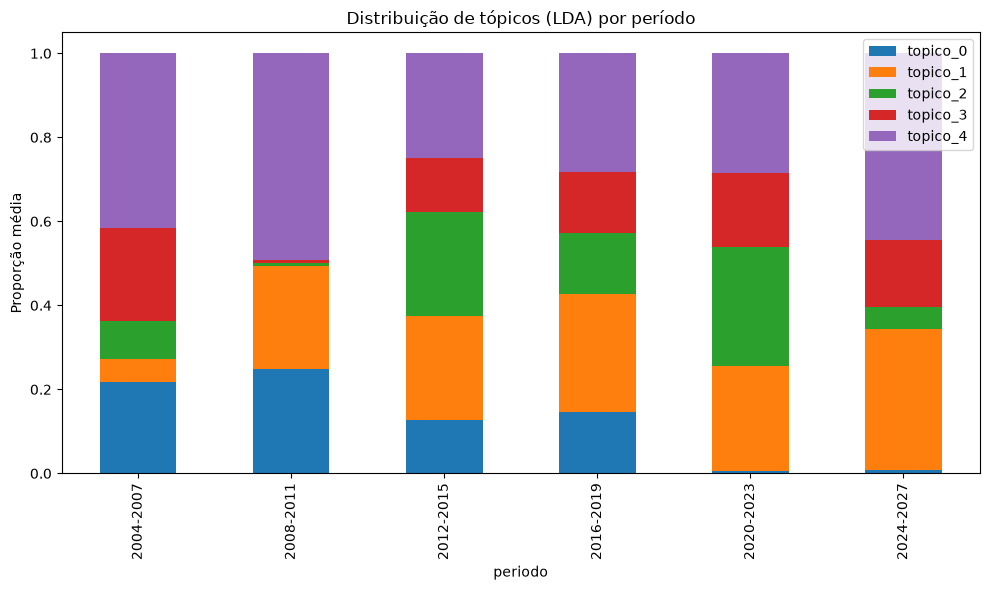

In [19]:
media_por_periodo.plot(kind="bar", stacked=True, figsize=(10, 6))
plt.title("Distribuição de tópicos (LDA) por período")
plt.ylabel("Proporção média")
plt.tight_layout()
plt.savefig(DIR_SAIDAS / "lda_topicos_por_periodo.png", dpi=150, bbox_inches="tight")
plt.show()

## Resultados complementares

Figuras e tabelas geradas pelos scripts da pasta `scripts/` (léxico, circularidade, instrumentos nas ações, valores orçados, composição x reescrita, termos distintivos). Estas células só leem arquivos de `saidas/`. Para atualizar, rode antes os scripts (ver `docs/achados.md`).

**Figura conceitual do método**

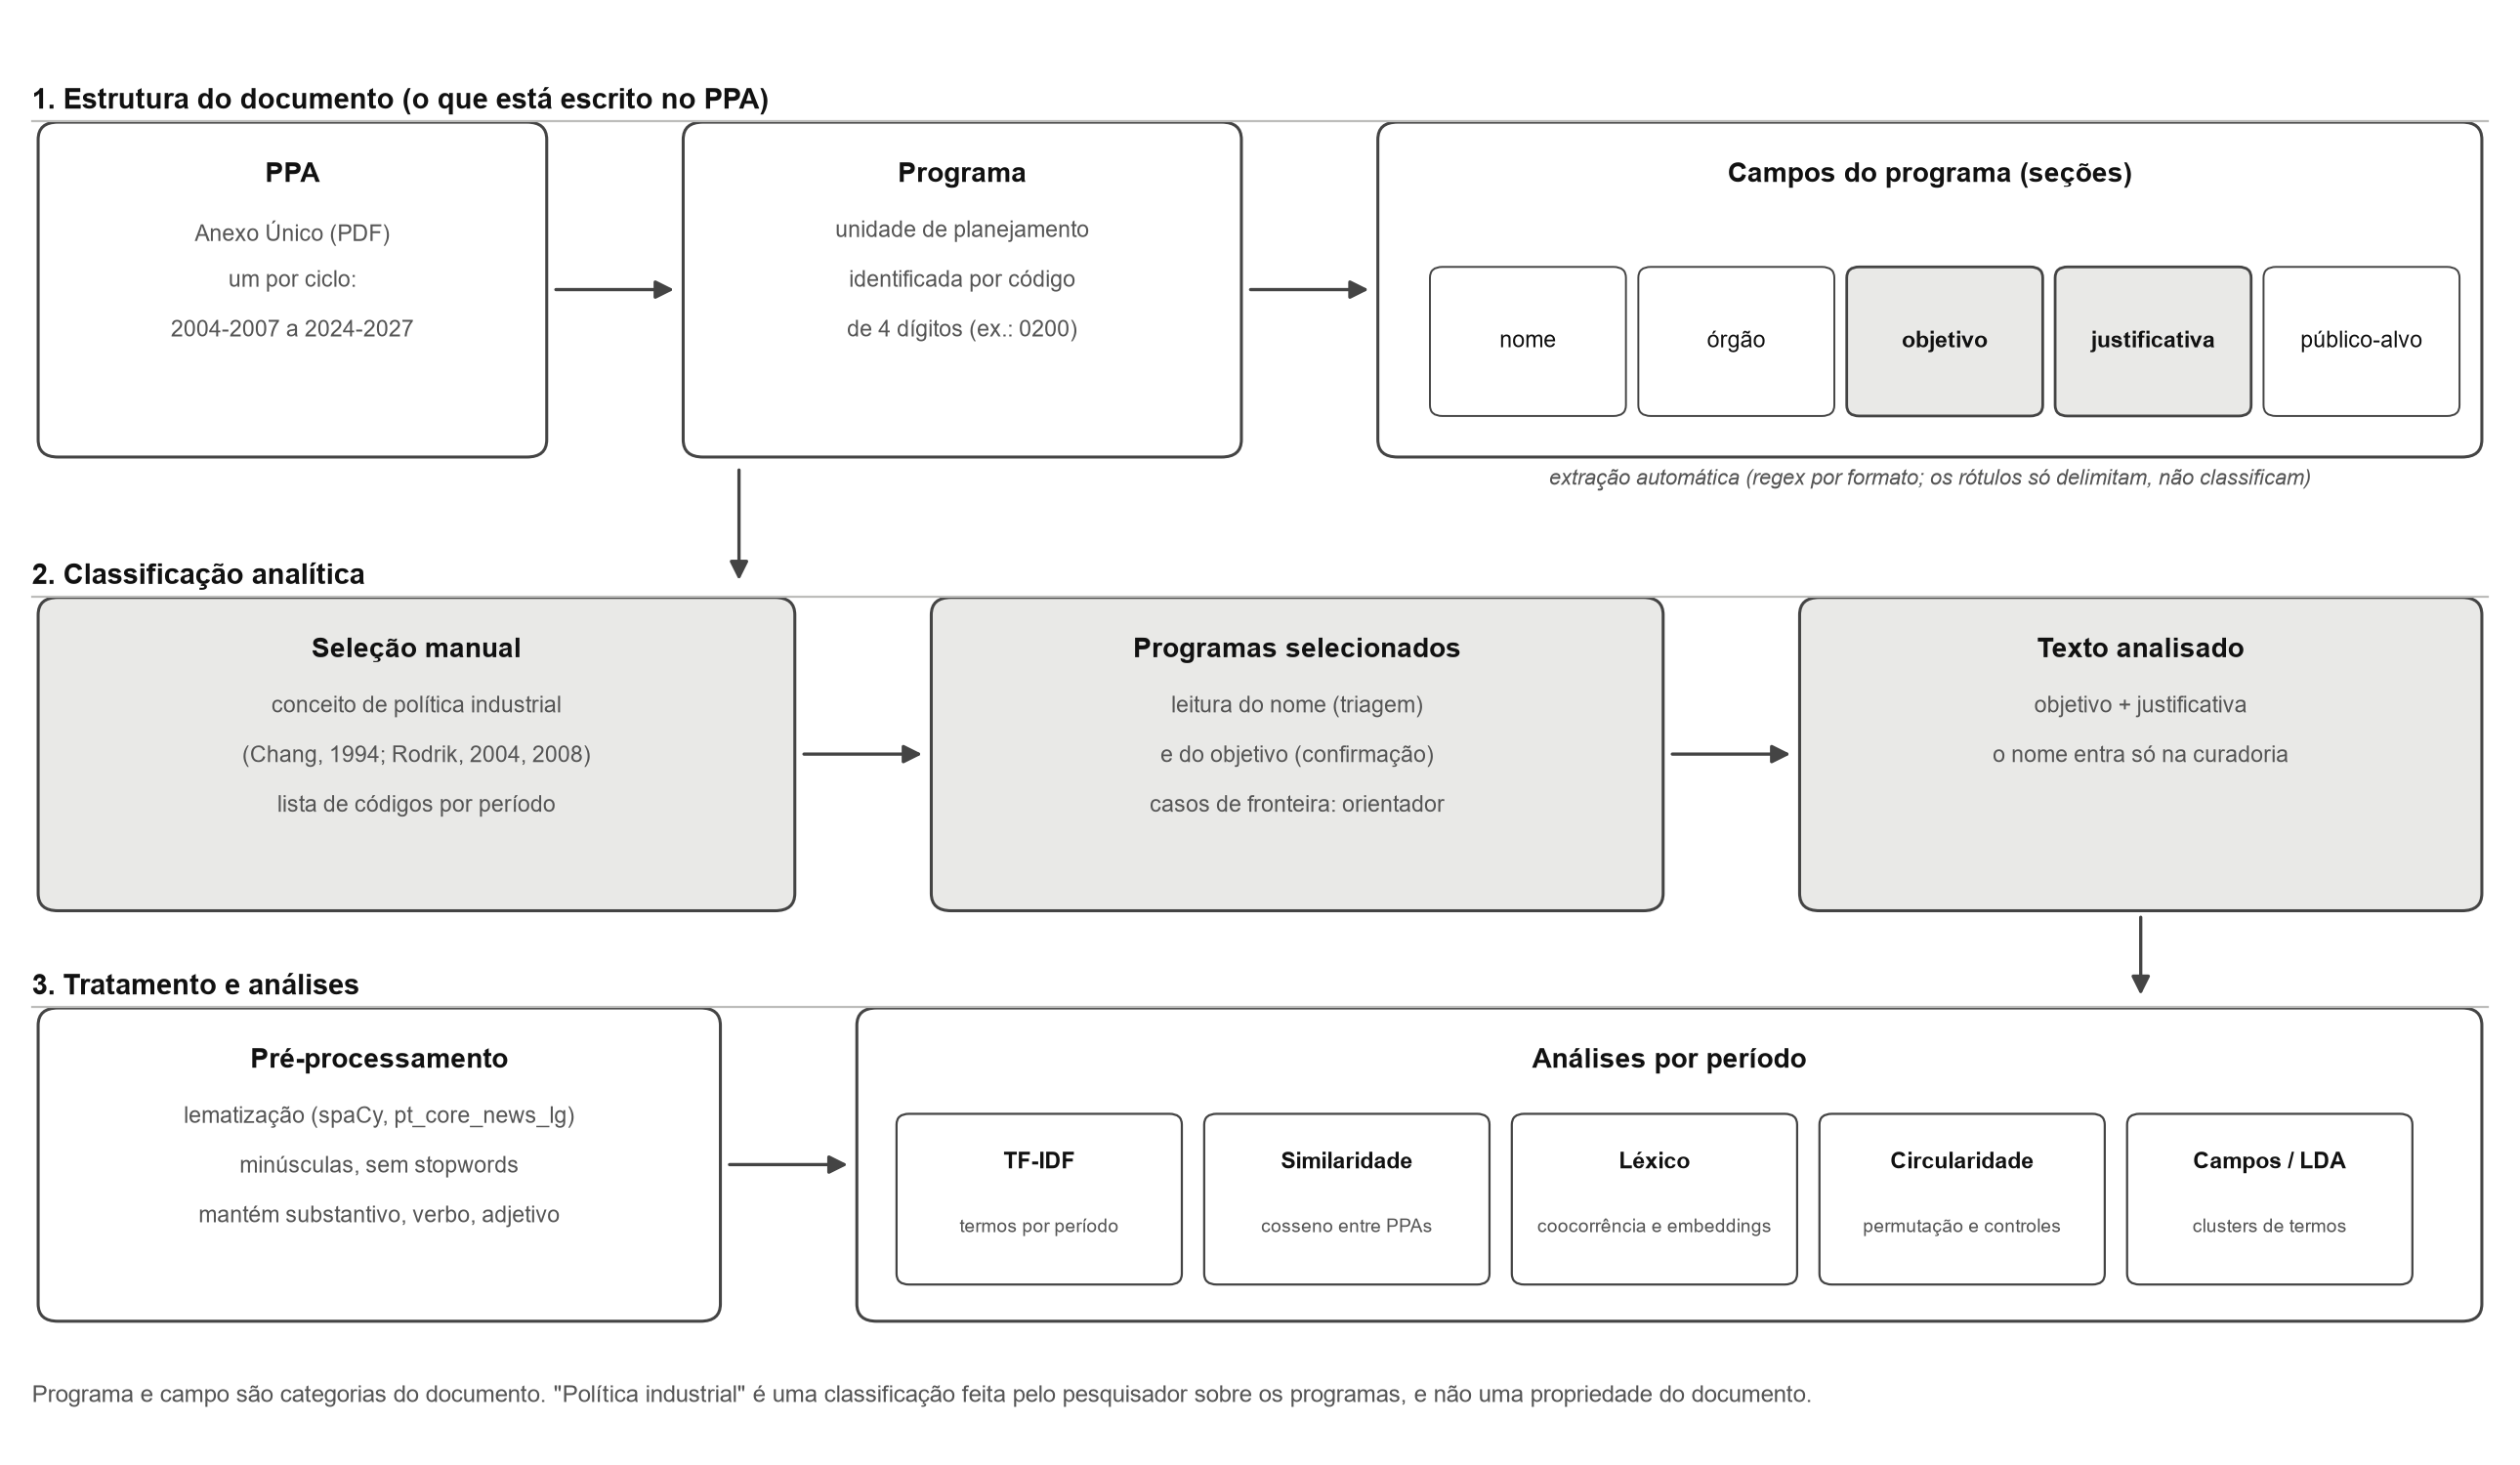

**Continuidade dos programas por série**

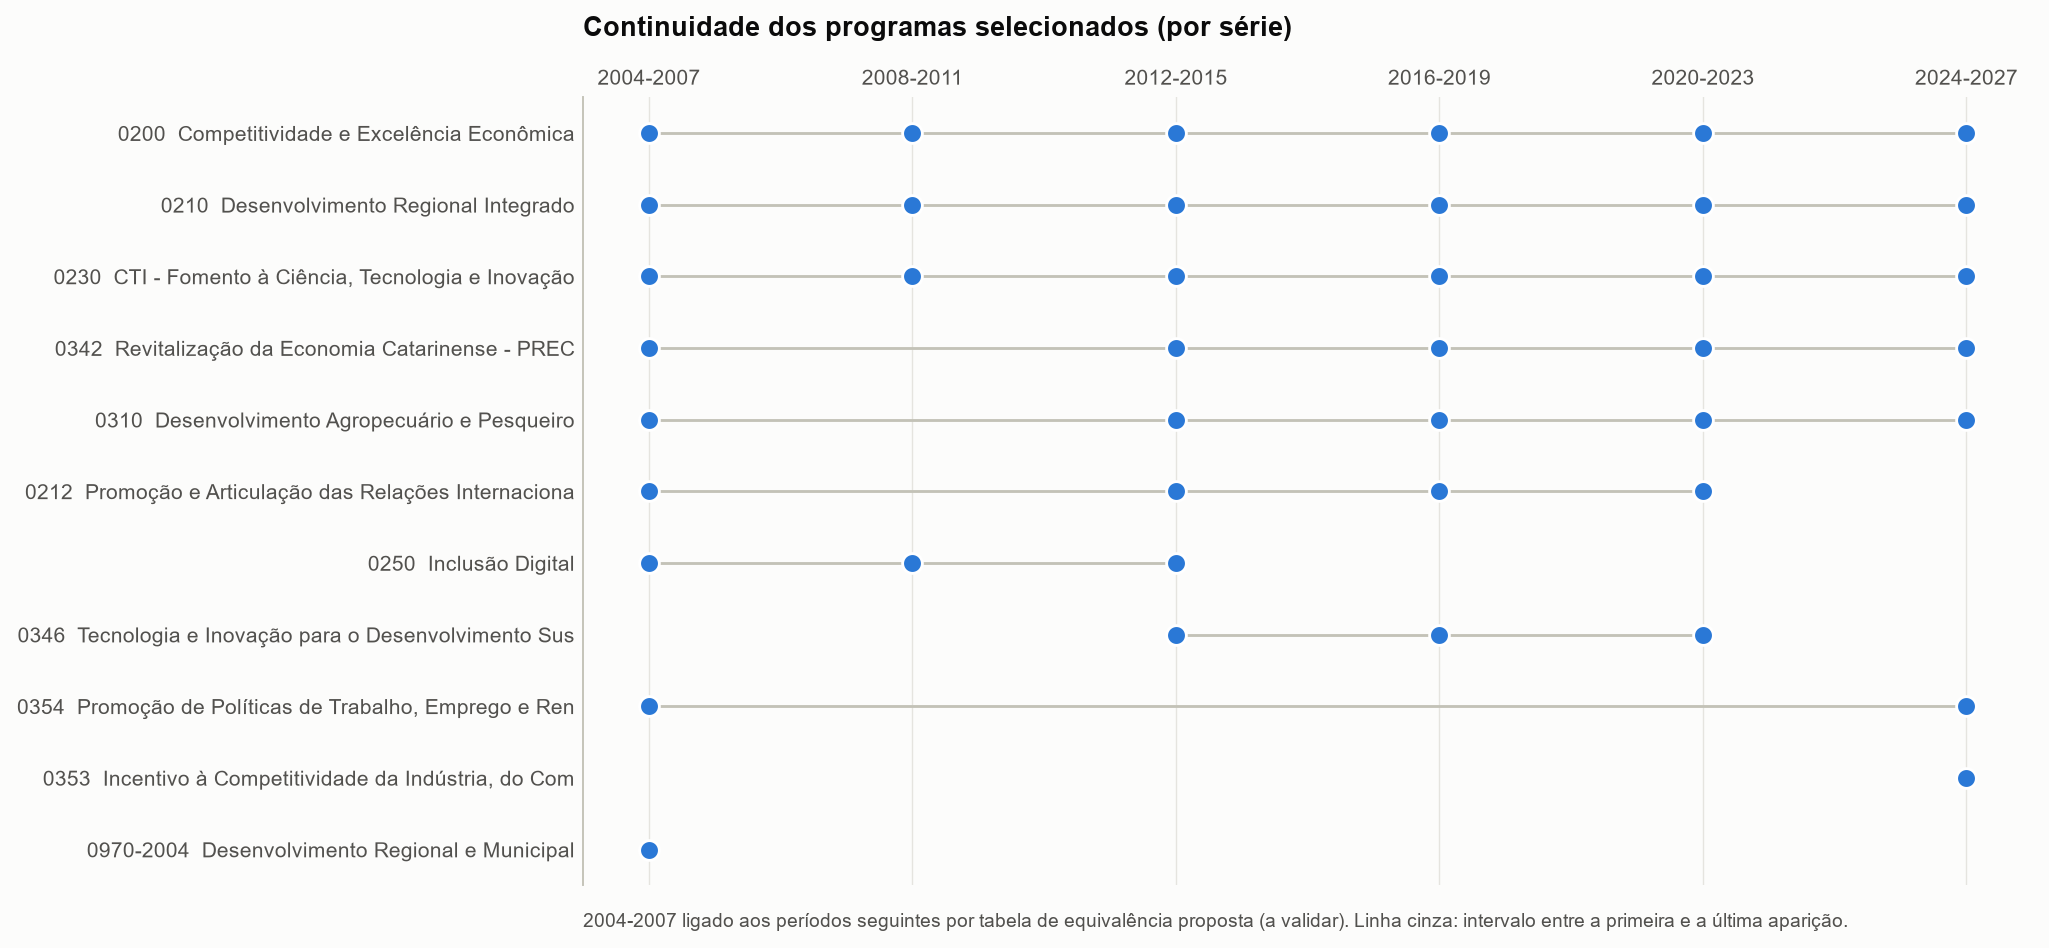

**Mudança entre períodos: composição x reescrita**

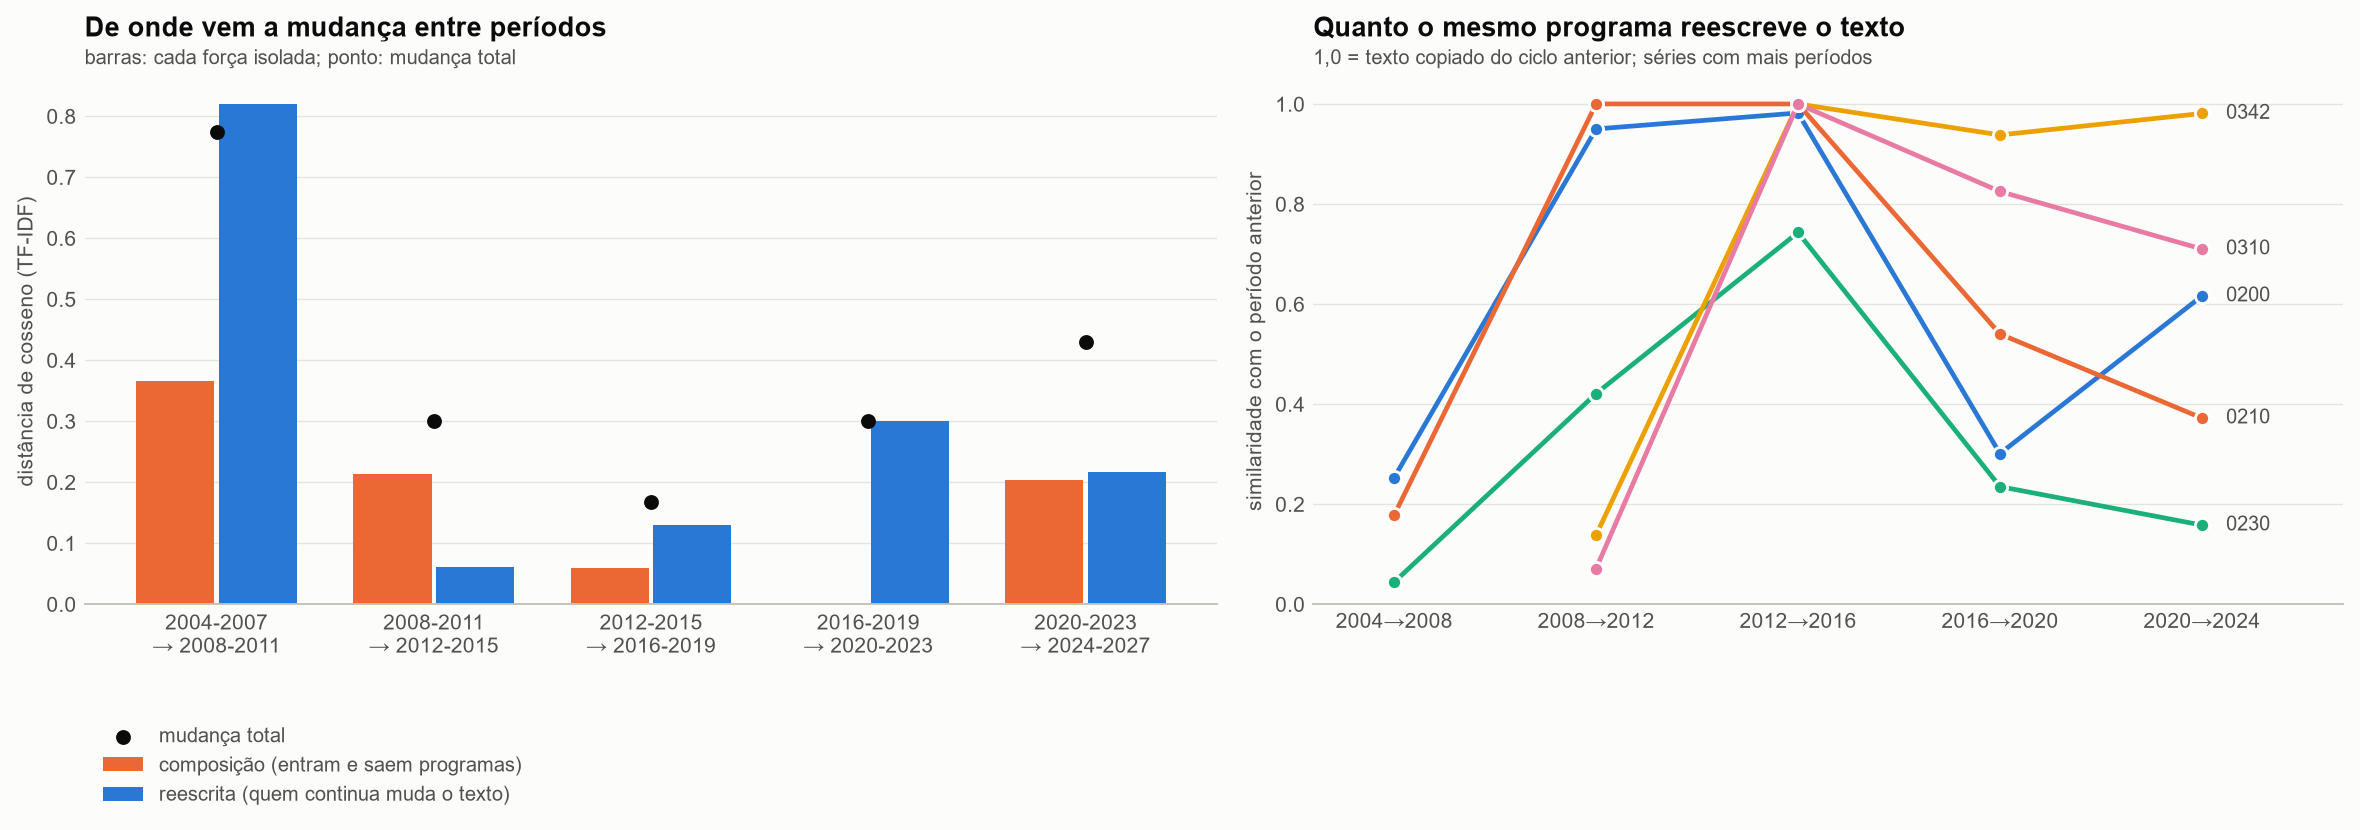

**Termos-chave contra o acaso e contra controles**

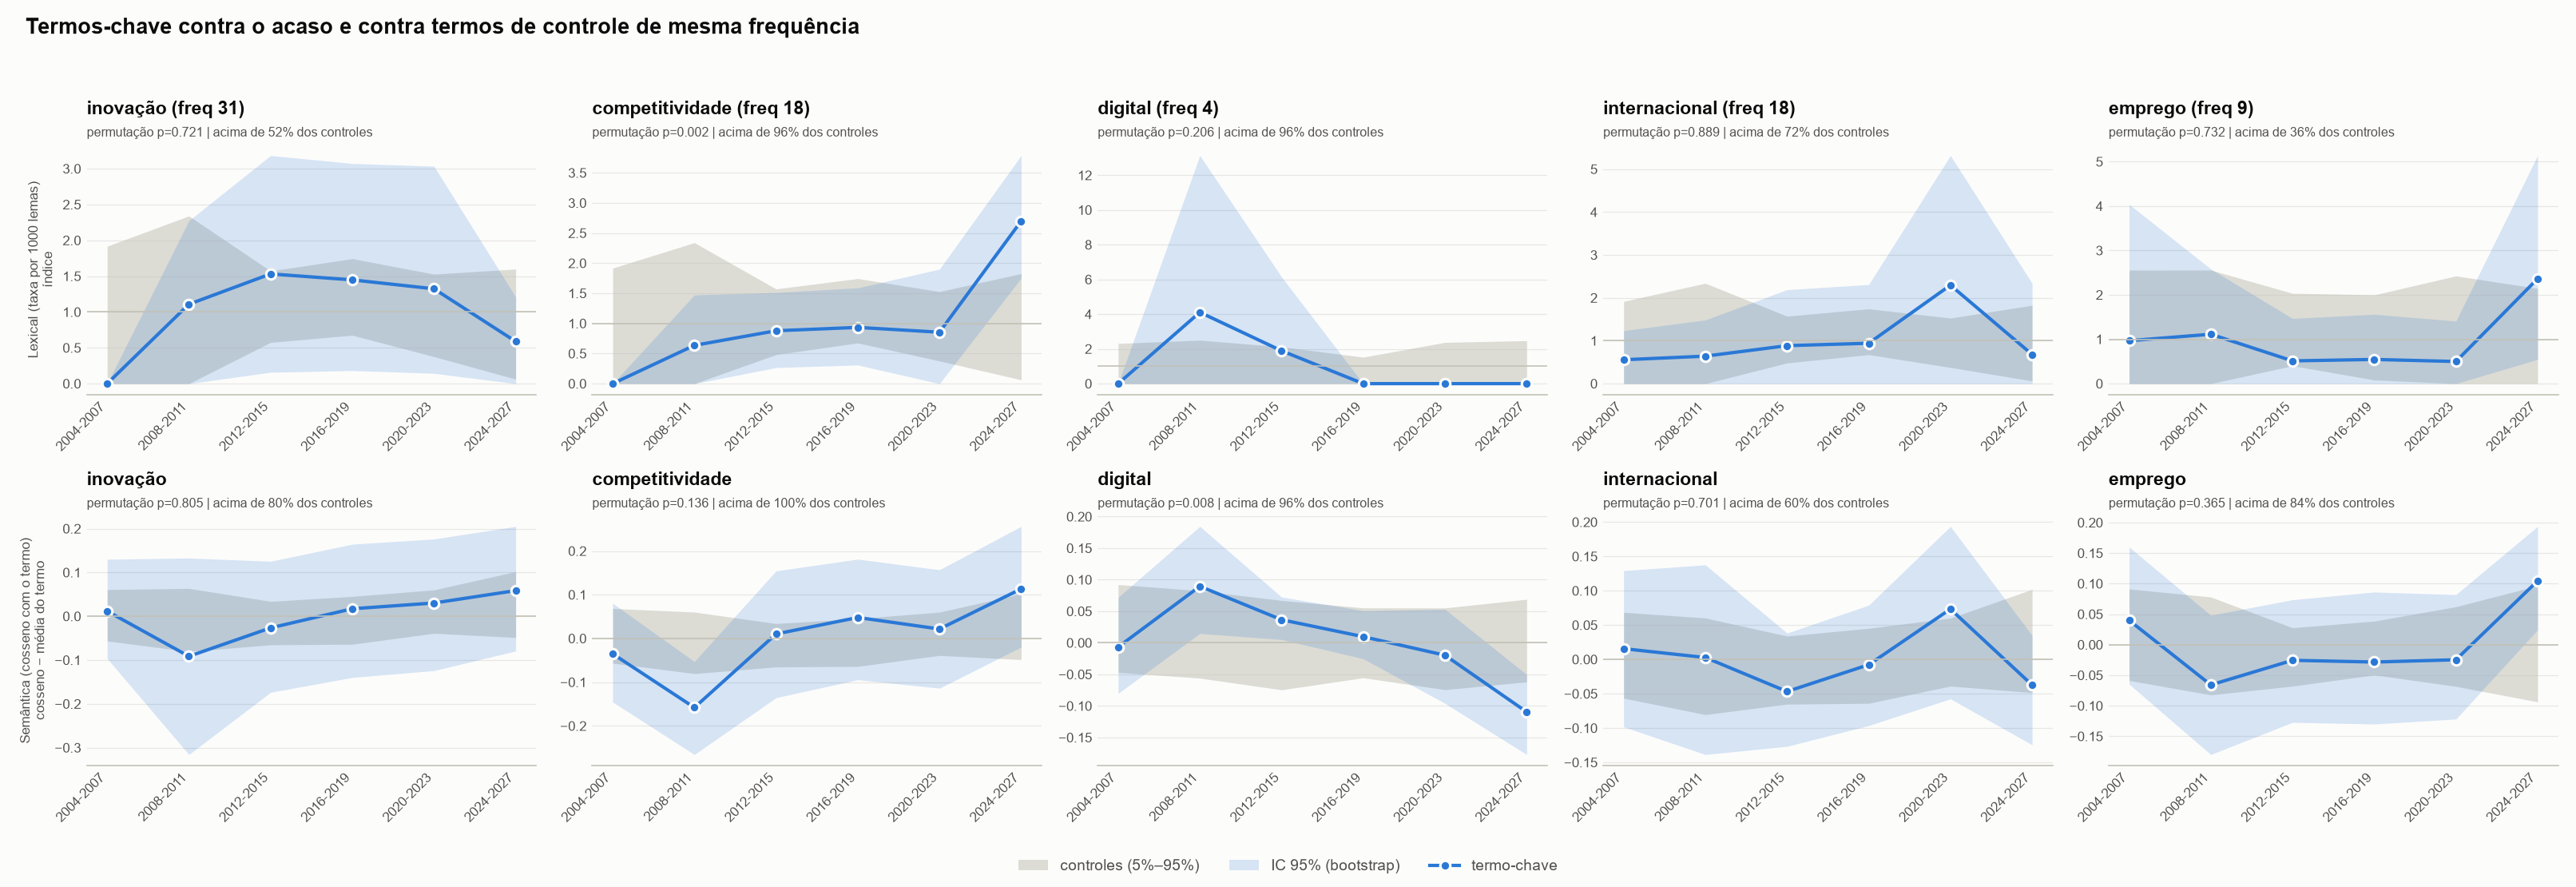

**Termos distintivos: 2004-2011 x 2020-2027**

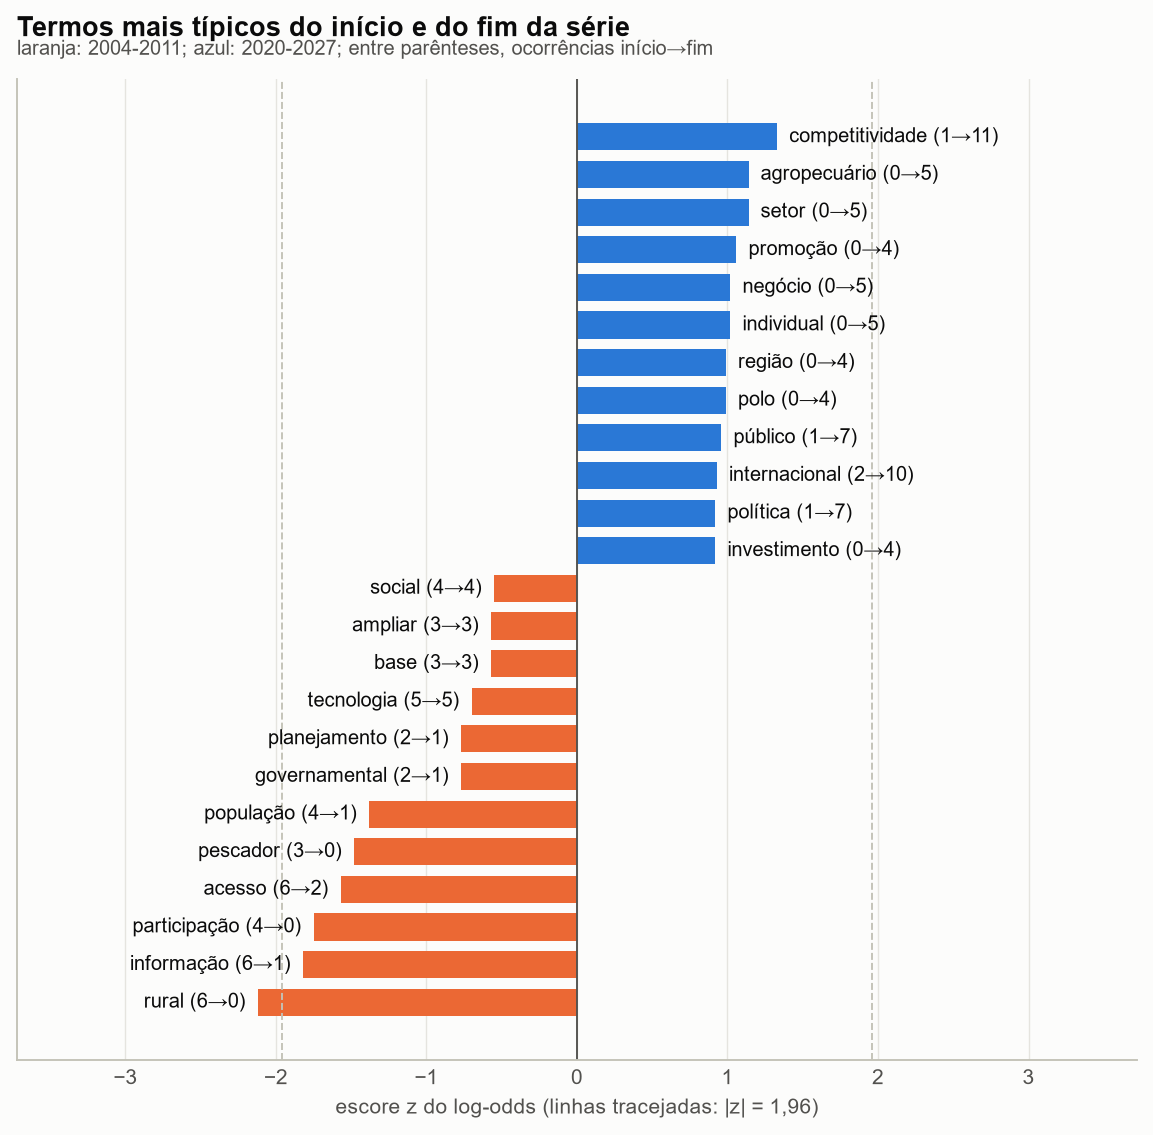

**Instrumentos nas ações e subações**

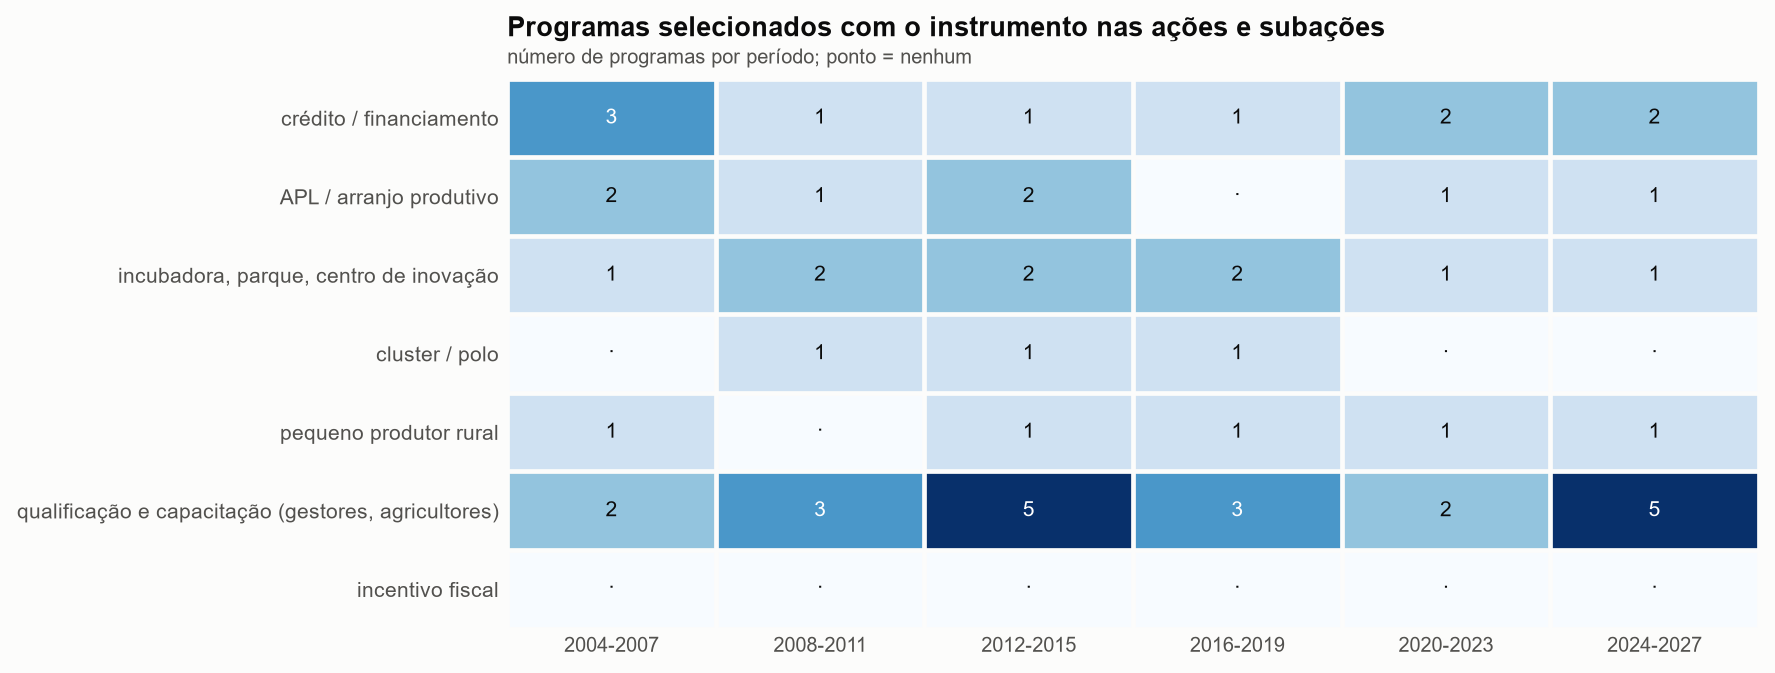

**Peso dos programas e dos instrumentos no valor do PPA**

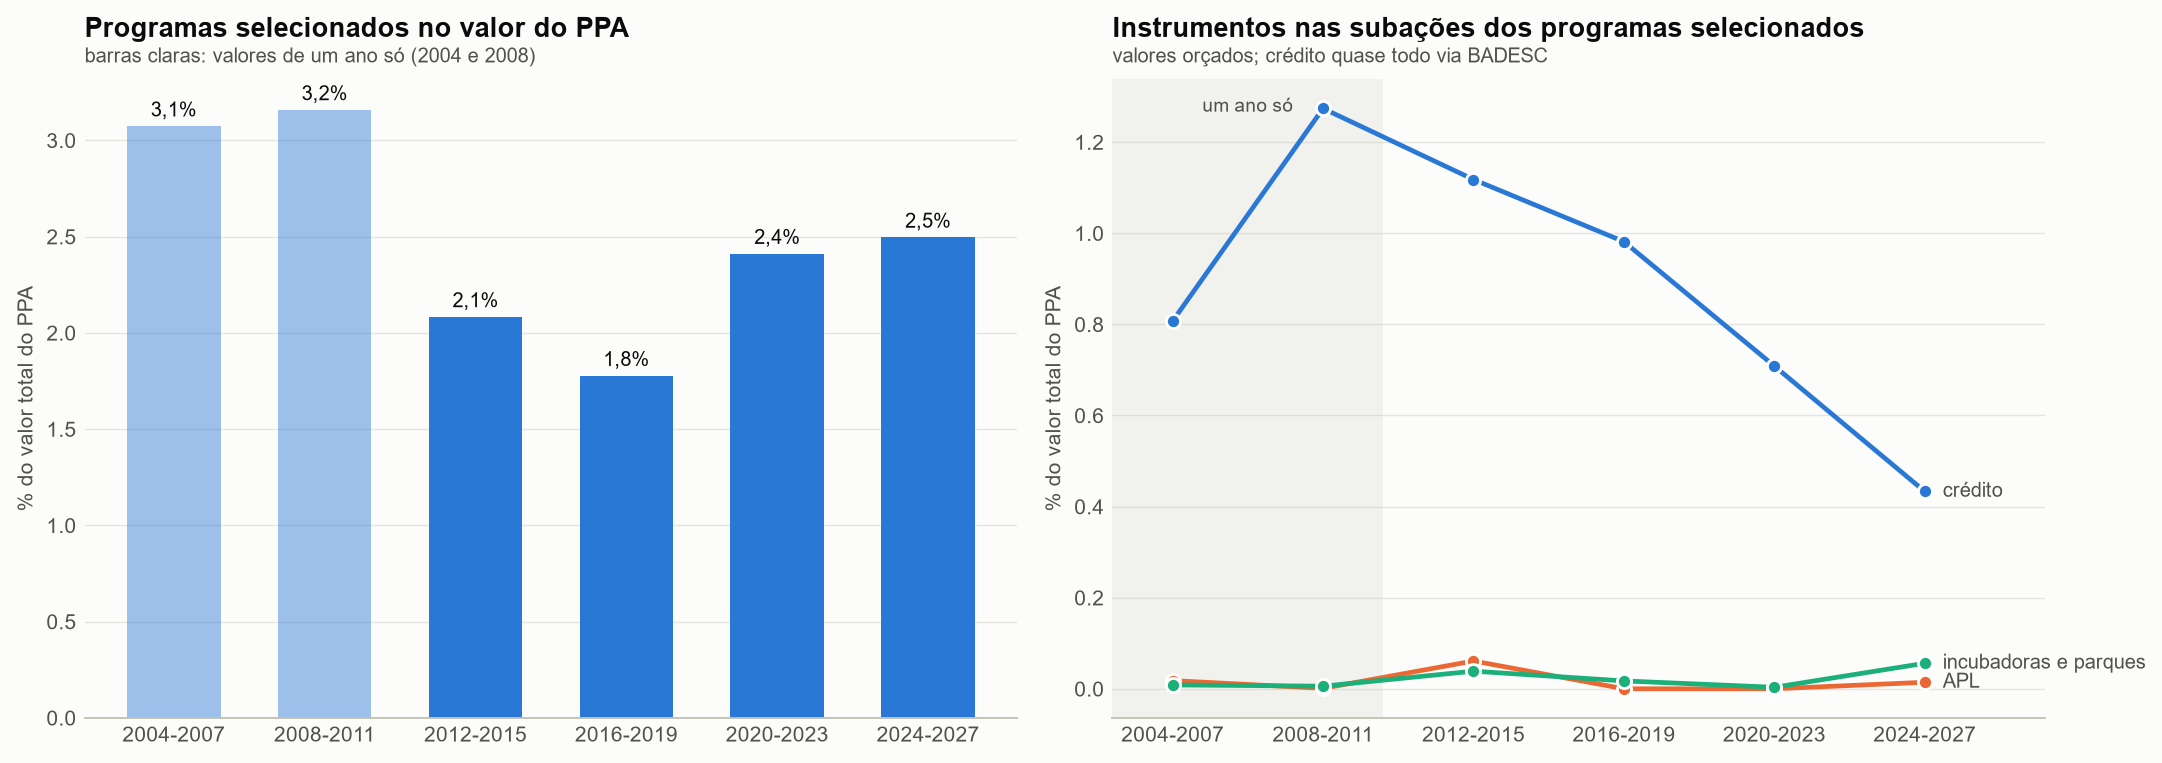

In [20]:
from IPython.display import Image, Markdown, display

figuras = [
    ("figura_conceitual_metodo.png", "Figura conceitual do método"),
    ("continuidade_series.png", "Continuidade dos programas por série"),
    ("composicao_vs_reescrita.png", "Mudança entre períodos: composição x reescrita"),
    ("circularidade_termos_chave_vs_controles.png", "Termos-chave contra o acaso e contra controles"),
    ("termos_distintivos_inicio_fim.png", "Termos distintivos: 2004-2011 x 2020-2027"),
    ("instrumentos_presenca_acoes.png", "Instrumentos nas ações e subações"),
    ("instrumentos_participacao_ppa.png", "Peso dos programas e dos instrumentos no valor do PPA"),
]
for arquivo, legenda in figuras:
    caminho = DIR_SAIDAS / arquivo
    if caminho.exists():
        display(Markdown(f"**{legenda}**"))
        display(Image(filename=str(caminho)))
    else:
        print("Ainda não gerada:", arquivo)

In [21]:
# Tabelas-resumo dos scripts
tabelas = {
    "Circularidade (p de permutação e % de controles superados)": ("circularidade_resumo.csv",
        ["termo", "medida", "p_perm_amplitude", "pct_acima_controles_amplitude"]),
    "Composição x reescrita": ("composicao_transicoes.csv",
        ["transicao", "mudanca_total", "efeito_composicao", "efeito_reescrita"]),
    "Valores orçados (participação no PPA, %)": ("valores_instrumentos.csv", None),
}
for titulo, (arquivo, colunas) in tabelas.items():
    caminho = DIR_SAIDAS / arquivo
    if not caminho.exists():
        print("Ainda não gerada:", arquivo)
        continue
    t = pd.read_csv(caminho, encoding="utf-8")
    if colunas is None:
        colunas = ["periodo"] + [c for c in t.columns if c.endswith("% documento")]
    display(Markdown(f"**{titulo}**"))
    display(t[colunas].round(3))

**Circularidade (p de permutação e % de controles superados)**

,termo,medida,p_perm_amplitude,pct_acima_controles_amplitude
0,inovação,lexical,0.720,52.0
1,inovação,semantica,0.805,80.0
2,competitividade,lexical,0.002,96.0
3,competitividade,semantica,0.136,100.0
4,digital,lexical,0.206,96.0
5,digital,semantica,0.008,96.0
6,internacional,lexical,0.889,72.0
7,internacional,semantica,0.701,60.0
8,emprego,lexical,0.732,36.0
9,emprego,semantica,0.365,84.0


**Composição x reescrita**

,transicao,mudanca_total,efeito_composicao,efeito_reescrita
0,2004-2007 → 2008-2011,0.774,0.365,0.820
1,2008-2011 → 2012-2015,0.301,0.213,0.061
2,2012-2015 → 2016-2019,0.168,0.060,0.129
3,2016-2019 → 2020-2023,0.301,0.000,0.301
4,2020-2023 → 2024-2027,0.429,0.203,0.216


**Valores orçados (participação no PPA, %)**

,periodo,crédito / financiamento | % documento,APL / arranjo produtivo | % documento,incubadora / parque / centro de inovação | % documento,polo | % documento
0,2004-2007,0.807,0.018,0.009,0.0
1,2008-2011,1.274,0.001,0.006,0.0
2,2012-2015,1.118,0.061,0.039,0.0
3,2016-2019,0.981,0.000,0.017,0.0
4,2020-2023,0.708,0.000,0.003,0.0
5,2024-2027,0.433,0.014,0.056,0.0
